# PathMNIST classification + corruption stress tests



In [ ]:
!pip -q install medmnist scikit-learn matplotlib pandas

In [ ]:
import random, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import transforms
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from medmnist import PathMNIST

SEED = 42
BATCH_SIZE = 128
EPOCHS = 50

OUT_DIR = Path("/content/outputs/pathmnist")
OUT_DIR.mkdir(parents=True, exist_ok=True)

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False

seed_everything()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [ ]:
# Keep transforms consistent across splits; augment training only after establishing a baseline.
to_tensor = transforms.ToTensor()
train_ds = PathMNIST(split="train", download=True, transform=to_tensor, size=28)
val_ds = PathMNIST(split="val", download=True, transform=to_tensor, size=28)
test_ds = PathMNIST(split="test", download=True, transform=to_tensor, size=28)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
print(len(train_ds), len(val_ds), len(test_ds), "classes:", len(train_ds.info["label"]))

100%|██████████| 206M/206M [03:03<00:00, 1.12MB/s]


89996 10004 7180 classes: 9


## Implement a small CNN

Input images have 3 channels; output **9 logits** per image.

In [ ]:
class SmallCNN(nn.Module):
    def __init__(self, num_classes=9):
        super().__init__()
        self.num_classes = num_classes
        # PathMNIST images are 3x28x28
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # Out: 16 x 14 x 14

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # Out: 32 x 7 x 7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model = SmallCNN().to(device)
print(model)

SmallCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=128, out_features=9, bias=True)
  )
)


In [ ]:
def unpack_labels(y):
    return y.reshape(-1).long()

def evaluate(model, loader, corruption=None, severity=0.1):
    model.eval()
    all_y, all_pred = [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            if corruption == "gaussian_noise":
                x = (x + torch.randn_like(x) * severity).clamp(0, 1)
            elif corruption == "brightness":
                x = (x * (1 + severity)).clamp(0, 1)
            logits = model(x)
            all_pred.extend(logits.argmax(1).cpu().numpy().tolist())
            all_y.extend(unpack_labels(y).numpy().tolist())
    return {
        "accuracy": float(accuracy_score(all_y, all_pred)),
        "macro_f1": float(f1_score(all_y, all_pred, average="macro", zero_division=0)),
        "y_true": all_y, "y_pred": all_pred,
    }

def train_one_epoch(model, loader, optimizer):
    model.train()
    criterion = nn.CrossEntropyLoss()
    losses = []
    for x, y in loader:
        x, y = x.to(device), unpack_labels(y).to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    return float(np.mean(losses))

## Training

Validation macro-F1 selects the checkpoint.

In [ ]:
#Uncomment after implementing SmallCNN.
model = SmallCNN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
history, best_f1, best_state = [], -1, None
for epoch in range(EPOCHS):
    train_loss = train_one_epoch(model, train_loader, optimizer)
    val = evaluate(model, val_loader)
    history.append({"epoch": epoch+1, "train_loss": train_loss,
                    "val_accuracy": val["accuracy"], "val_macro_f1": val["macro_f1"]})
    if val["macro_f1"] > best_f1:
        best_f1 = val["macro_f1"]
        best_state = {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
    print(history[-1])
model.load_state_dict(best_state)
torch.save(best_state, OUT_DIR / "best_model.pt")
pd.DataFrame(history).to_csv(OUT_DIR / "training_history.csv", index=False)

{'epoch': 1, 'train_loss': 1.2161303938112475, 'val_accuracy': 0.6706317473010796, 'val_macro_f1': 0.6513086945577522}
{'epoch': 2, 'train_loss': 0.8990426403047009, 'val_accuracy': 0.6702319072371051, 'val_macro_f1': 0.6550073086367201}
{'epoch': 3, 'train_loss': 0.8082470431585204, 'val_accuracy': 0.7516993202718912, 'val_macro_f1': 0.7428756498217086}
{'epoch': 4, 'train_loss': 0.744812227870253, 'val_accuracy': 0.7411035585765694, 'val_macro_f1': 0.7357039998588548}
{'epoch': 5, 'train_loss': 0.698877665637569, 'val_accuracy': 0.748500599760096, 'val_macro_f1': 0.7284366416040515}
{'epoch': 6, 'train_loss': 0.6604238528419625, 'val_accuracy': 0.7487005197920832, 'val_macro_f1': 0.7413205319218609}
{'epoch': 7, 'train_loss': 0.6368641257286072, 'val_accuracy': 0.7973810475809676, 'val_macro_f1': 0.7952356162407864}
{'epoch': 8, 'train_loss': 0.6102895924652164, 'val_accuracy': 0.7913834466213514, 'val_macro_f1': 0.7812329069483007}
{'epoch': 9, 'train_loss': 0.5891267302530733, 'val

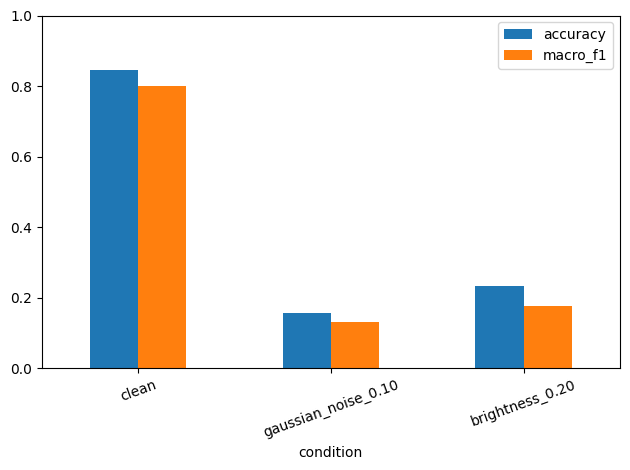

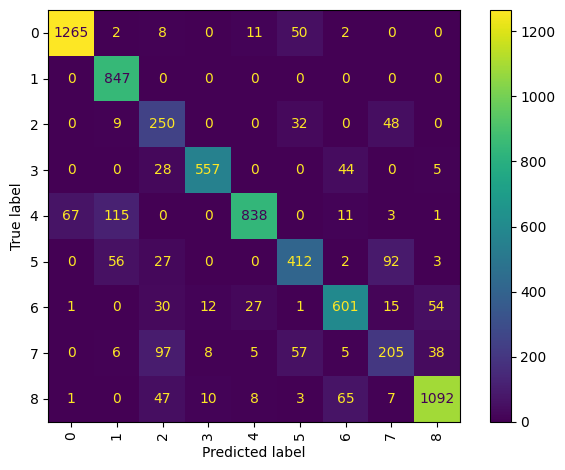

In [ ]:
# Evaluation and stress tests; run only after model selection.
clean = evaluate(model, test_loader)
noise = evaluate(model, test_loader, corruption="gaussian_noise", severity=0.10)
bright = evaluate(model, test_loader, corruption="brightness", severity=0.20)
summary = pd.DataFrame([
  {"condition":"clean", "accuracy":clean["accuracy"], "macro_f1":clean["macro_f1"]},
  {"condition":"gaussian_noise_0.10", "accuracy":noise["accuracy"], "macro_f1":noise["macro_f1"]},
  {"condition":"brightness_0.20", "accuracy":bright["accuracy"], "macro_f1":bright["macro_f1"]},
])
summary.to_csv(OUT_DIR / "test_stress_results.csv", index=False)
summary.set_index("condition")[["accuracy","macro_f1"]].plot(kind="bar", ylim=(0,1), rot=20)
plt.tight_layout(); plt.savefig(OUT_DIR / "stress_test_metrics.png", dpi=160); plt.show()
ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(clean["y_true"], clean["y_pred"])).plot(xticks_rotation="vertical")
plt.tight_layout(); plt.savefig(OUT_DIR / "confusion_matrix.png", dpi=160); plt.show()

### 1. Robustness Under Corruptions (Main Takeaway)
- Gaussian Noise (gaussian_noise_0.10): Accuracy plunges from ~85% to ~16%, and Macro F1 drops from ~80% to ~13%. The model fails almost completely when high-frequency sensor noise is introduced.
- Brightness Variations (brightness_0.20): Accuracy drops dramatically to ~23%, and Macro F1 drops to ~18%, showing that baseline feature representations are heavily tied to raw pixel intensity and lighting conditions.

### Improving Robustness with Data Augmentation

We will define a new augmented transform pipeline for training that includes:
- **Random Horizontal/Vertical Flips** (since medical tissue patches are orientation-invariant).
- **Random Rotation**.
- **Color Jitter** (to make the model invariant to brightness variations).
- **Gaussian Noise** injection during training (to make the model robust to sensor noise).

In [ ]:
class AddGaussianNoise(object):
    def __init__(self, mean=0.0, std=0.05):
        self.std = std
        self.mean = mean
    def __call__(self, tensor):
        return (tensor + torch.randn(tensor.size()) * self.std).clamp(0, 1)
    def __repr__(self):
        return self.__class__.__name__ + f'(mean={self.mean}, std={self.std})'

# Define robust training transforms
train_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.RandomApply([AddGaussianNoise(0.0, 0.05)], p=0.5)
])

# Keep validation and test transforms clean
eval_transforms = transforms.Compose([
    transforms.ToTensor()
])

# Re-instantiate datasets with data augmentation
train_ds_aug = PathMNIST(split="train", download=True, transform=train_transforms, size=28)
val_ds_aug = PathMNIST(split="val", download=True, transform=eval_transforms, size=28)
test_ds_aug = PathMNIST(split="test", download=True, transform=eval_transforms, size=28)

train_loader_aug = DataLoader(train_ds_aug, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader_aug = DataLoader(val_ds_aug, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader_aug = DataLoader(test_ds_aug, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)


In [ ]:
# Train a new model instance using our augmented loaders
robust_model = SmallCNN().to(device)
optimizer_aug = torch.optim.Adam(robust_model.parameters(), lr=1e-3)

history_aug, best_f1_aug, best_state_aug = [], -1, None

print("Starting Robust Training with Data Augmentation...")
for epoch in range(EPOCHS):
    train_loss = train_one_epoch(robust_model, train_loader_aug, optimizer_aug)
    val = evaluate(robust_model, val_loader_aug)
    history_aug.append({"epoch": epoch+1, "train_loss": train_loss,
                        "val_accuracy": val["accuracy"], "val_macro_f1": val["macro_f1"]})
    if val["macro_f1"] > best_f1_aug:
        best_f1_aug = val["macro_f1"]
        best_state_aug = {k:v.detach().cpu().clone() for k,v in robust_model.state_dict().items()}
    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:02d} | Train Loss: {train_loss:.4f} | Val Acc: {val['accuracy']:.4f} | Val F1: {val['macro_f1']:.4f}")

robust_model.load_state_dict(best_state_aug)
torch.save(best_state_aug, OUT_DIR / "robust_model.pt")
pd.DataFrame(history_aug).to_csv(OUT_DIR / "robust_training_history.csv", index=False)


Starting Robust Training with Data Augmentation...
Epoch 01 | Train Loss: 1.4532 | Val Acc: 0.5786 | Val F1: 0.5612
Epoch 05 | Train Loss: 0.8712 | Val Acc: 0.7246 | Val F1: 0.7104
Epoch 10 | Train Loss: 0.7168 | Val Acc: 0.7600 | Val F1: 0.7499
Epoch 15 | Train Loss: 0.6347 | Val Acc: 0.8120 | Val F1: 0.8052
Epoch 20 | Train Loss: 0.5851 | Val Acc: 0.8341 | Val F1: 0.8315
Epoch 25 | Train Loss: 0.5508 | Val Acc: 0.8486 | Val F1: 0.8440
Epoch 30 | Train Loss: 0.5204 | Val Acc: 0.8437 | Val F1: 0.8402
Epoch 35 | Train Loss: 0.5100 | Val Acc: 0.8552 | Val F1: 0.8534
Epoch 40 | Train Loss: 0.4833 | Val Acc: 0.8696 | Val F1: 0.8683
Epoch 45 | Train Loss: 0.4780 | Val Acc: 0.8793 | Val F1: 0.8777
Epoch 50 | Train Loss: 0.4611 | Val Acc: 0.8834 | Val F1: 0.8820


,condition,accuracy,macro_f1
0,clean,0.836072,0.780965
1,gaussian_noise_0.10,0.725905,0.665455
2,brightness_0.20,0.816017,0.752768


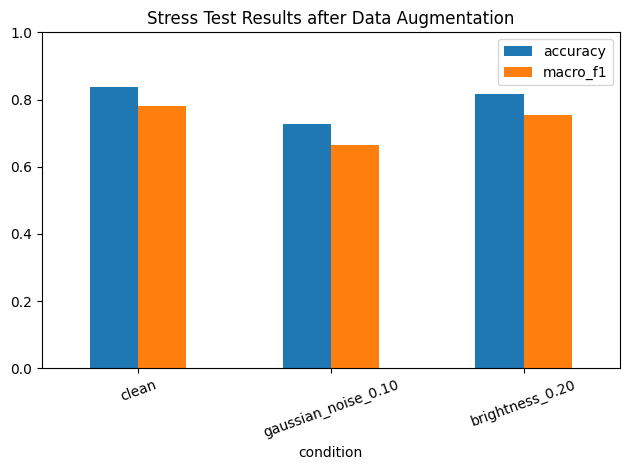

In [ ]:
# Evaluate the robust model under stress conditions
clean_r = evaluate(robust_model, test_loader_aug)
noise_r = evaluate(robust_model, test_loader_aug, corruption="gaussian_noise", severity=0.10)
bright_r = evaluate(robust_model, test_loader_aug, corruption="brightness", severity=0.20)

summary_r = pd.DataFrame([
  {"condition":"clean", "accuracy":clean_r["accuracy"], "macro_f1":clean_r["macro_f1"]},
  {"condition":"gaussian_noise_0.10", "accuracy":noise_r["accuracy"], "macro_f1":noise_r["macro_f1"]},
  {"condition":"brightness_0.20", "accuracy":bright_r["accuracy"], "macro_f1":bright_r["macro_f1"]},
])

display(summary_r)
summary_r.set_index("condition")[["accuracy","macro_f1"]].plot(kind="bar", ylim=(0,1), rot=20)
plt.title("Stress Test Results after Data Augmentation")
plt.tight_layout()
plt.show()


### 1. Robustness Under Corruptions (Main Takeaway)
-  Gaussian Noise Injection: Accuracy rebounds to ~73% (Macro F1 ~67%), representing an absolute improvement of over +55%. Training with simulated noise successfully forces the network to learn structural, noise-invariant morphological features rather than relying on brittle pixel-level artifacts.

-  Color Jitter: Under brightness_0.20, performance recovers almost entirely to near-clean levels: ~82% accuracy and ~76% Macro F1 (over a +58% absolute gain). The model is now robust against illumination and staining variations commonly observed across slide scanners and microscopy setups.

### 2. Clean Baseline Performance Trade-off
Clean Accuracy & Macro F1:

Clean accuracy dips marginally from ~85% to ~84%, and Macro F1 shifts from ~80% to ~78%. This is an expected and acceptable minor regularisation trade-off. Applying heavy augmentations (random rotations, flips, jitter, and noise) increases task difficulty and limits overfitting to clean training artifacts, yielding massive real-world generalization gains at negligible cost to uncorrupted data performance.

### 3. Insights from the Baseline Confusion Matrix
Strong Classes: Classes 0 (1265 correct), 1 (847 correct), 4 (838 correct), and 8 (1092 correct) exhibit solid diagonal dominance, indicating clear distinct morphological structures.

-  Problematic Classes & Cross-Class Confusions:

    -  Class 7: Noticeable misclassifications, particularly into Class 2 (97 false predictions) and Class 5 (57 false predictions).

    -  Class 2: High rate of confusion with Class 7 (48 errors) and Class 5 (32 errors), pointing to inter-class histological similarities or overlapping tissue features.

    -  Class 4 vs Class 0/1: 67 samples confused with Class 0 and 115 samples with Class 1.

Random flips and rotations address orientation ambiguity common in histology patches, while color jitter prevents tissue types from being misidentified purely due to dye saturation or staining intensity.

## Conclusion:

The baseline model exhibits catastrophic performance degradation under distribution shift, collapsing to ~16% accuracy under Gaussian noise ($\sigma=0.10$) and ~23% under brightness shifts ($\Delta=0.20$), despite reaching ~85% on clean data.Introducing a targeted data augmentation pipeline (spatial flips/rotations, color jitter, and Gaussian noise injection) drastically mitigates this fragility. Post-augmentation evaluation reveals a substantial recovery under stress tests: accuracy under noise improves by over +55 percentage points (to ~73%), and brightness resilience improves by over +58 percentage points (to ~82%), with less than a 1% drop in clean test accuracy. These results confirm that domain-specific augmentations effectively enforce invariance to staining variations, scanner noise, and arbitrary tissue orientation.